<a href="https://colab.research.google.com/github/24219332-collab/WIX1002/blob/main/Tutorial3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
df = pd.read_csv('train.csv')
display(df.head())

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [12]:
print("Rows and columns:", df.shape)
print("Repeated Id values:", df["Id"].duplicated().sum())
print("SalePrice summary:")
print(df["SalePrice"].describe())

Rows and columns: (1460, 81)
Repeated Id values: 0
SalePrice summary:
count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


The dataset is good. There are 1,460 observations and 81 columns

In [13]:
print("All columns:")
print(df.columns.tolist())
print("Number of columns:", len(df.columns))
print("Possible input columns (excluding SalePrice and Id):", len(df.columns) - 2)


All columns:
['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual', 'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolAr

There are 81 columns: one outcome (SalePrice), one identifier (Id), and 79 other columns.

In [4]:
print("Number of houses (observations):", len(df))

Number of houses (observations): 1460


1,460 observations in the standard Kaggle train.csv. That is enough to calculate summaries and create beginner charts, but whether it is sufficient for a reliable prediction model depends.

In [10]:
print(df.dtypes)


Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
                  ...   
MoSold             int64
YrSold             int64
SaleType          object
SaleCondition     object
SalePrice          int64
Length: 81, dtype: object


int64 means whole numbers (e.g., SalePrice or LotArea); float64 means decimal numbers (e.g., LotFrontage); and object usually means text or categories (e.g., Neighborhood or HouseStyle).

In [25]:
missing_data = df.isnull().sum()
columns_with_nulls = missing_data[missing_data > 0]

print("Number of columns with null values:", len(columns_with_nulls))

print(columns_with_nulls)


Number of columns with null values: 19
LotFrontage      259
Alley           1369
MasVnrType       872
MasVnrArea         8
BsmtQual          37
BsmtCond          37
BsmtExposure      38
BsmtFinType1      37
BsmtFinType2      38
Electrical         1
FireplaceQu      690
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
PoolQC          1453
Fence           1179
MiscFeature     1406
dtype: int64


19 columns with null values.

In [7]:
target = "SalePrice"
features = df.drop(columns=["SalePrice", "Id"])
print("Target:", target)
print("Example feature columns:", features.columns.tolist()[:10])

Target: SalePrice
Example feature columns: ['MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig']


The target output is the SalePrice column.The features are the remaining 79 columns.

In [8]:
has_missing = df.isnull().values.any()
print("Does it have missing values?:", has_missing)
print("Total missing data points:", df.isnull().sum().sum())
print("\n--- Rows missing 'LotFrontage' data ---")
display(df[df['LotFrontage'].isnull()].head())

Does it have missing values?: True
Total missing data points: 7829

--- Rows missing 'LotFrontage' data ---


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
12,13,20,RL,NaN,12968,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,144000
14,15,20,RL,NaN,10920,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,GdWo,NaN,0,5,2008,WD,Normal,157000
16,17,20,RL,NaN,11241,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,700,3,2010,WD,Normal,149000
24,25,20,RL,NaN,8246,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,5,2010,WD,Normal,154000


Average Sale Price by Central Air:
CentralAir
N    105264.07
Y    186186.71
Name: SalePrice, dtype: float64


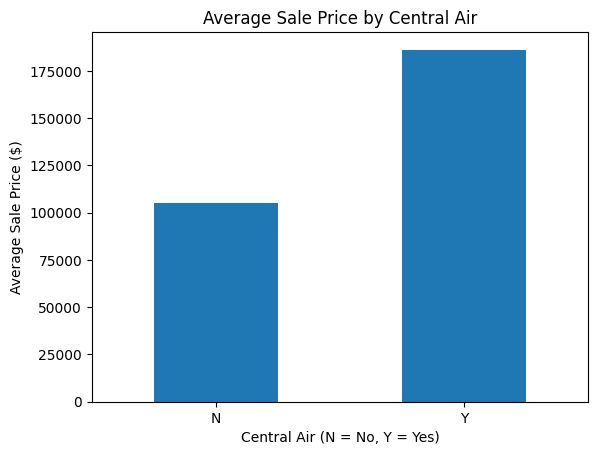

In [26]:
import matplotlib.pyplot as plt

air_con_price = df.groupby("CentralAir")["SalePrice"].mean()
print("Average Sale Price by Central Air:")
print(air_con_price.round(2))

air_con_price.plot(kind="bar")
plt.title("Average Sale Price by Central Air")
plt.xlabel("Central Air (N = No, Y = Yes)")
plt.ylabel("Average Sale Price ($)")
plt.xticks(rotation=0)
plt.show()

How does Central Air Conditioning affect the average sale price? This is suitable because CentralAir (N, Y) and SalePrice are both present. The following table and chart show average sale prices rather than only house counts.